In [1]:
import pandas as pd
import matplotlib.pyplot as plt


In [2]:
df = pd.read_csv("../data/Base.csv")

print(df.shape)
display(df.head())

(1000000, 32)


,fraud_bool,income,name_email_similarity,prev_address_months_count,current_address_months_count,customer_age,days_since_request,intended_balcon_amount,payment_type,zip_count_4w,...,has_other_cards,proposed_credit_limit,foreign_request,source,session_length_in_minutes,device_os,keep_alive_session,device_distinct_emails_8w,device_fraud_count,month
0,0,0.3,0.986506,-1,25,40,0.006735,102.453711,AA,1059,...,0,1500.0,0,INTERNET,16.224843,linux,1,1,0,0
1,0,0.8,0.617426,-1,89,20,0.010095,-0.849551,AD,1658,...,0,1500.0,0,INTERNET,3.363854,other,1,1,0,0
2,0,0.8,0.996707,9,14,40,0.012316,-1.490386,AB,1095,...,0,200.0,0,INTERNET,22.730559,windows,0,1,0,0
3,0,0.6,0.475100,11,14,30,0.006991,-1.863101,AB,3483,...,0,200.0,0,INTERNET,15.215816,linux,1,1,0,0
4,0,0.9,0.842307,-1,29,40,5.742626,47.152498,AA,2339,...,0,200.0,0,INTERNET,3.743048,other,0,1,0,0


In [3]:
df.columns

Index(['fraud_bool', 'income', 'name_email_similarity',
       'prev_address_months_count', 'current_address_months_count',
       'customer_age', 'days_since_request', 'intended_balcon_amount',
       'payment_type', 'zip_count_4w', 'velocity_6h', 'velocity_24h',
       'velocity_4w', 'bank_branch_count_8w',
       'date_of_birth_distinct_emails_4w', 'employment_status',
       'credit_risk_score', 'email_is_free', 'housing_status',
       'phone_home_valid', 'phone_mobile_valid', 'bank_months_count',
       'has_other_cards', 'proposed_credit_limit', 'foreign_request', 'source',
       'session_length_in_minutes', 'device_os', 'keep_alive_session',
       'device_distinct_emails_8w', 'device_fraud_count', 'month'],
      dtype='str')

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000000 entries, 0 to 999999
Data columns (total 32 columns):
 #   Column                            Non-Null Count    Dtype  
---  ------                            --------------    -----  
 0   fraud_bool                        1000000 non-null  int64  
 1   income                            1000000 non-null  float64
 2   name_email_similarity             1000000 non-null  float64
 3   prev_address_months_count         1000000 non-null  int64  
 4   current_address_months_count      1000000 non-null  int64  
 5   customer_age                      1000000 non-null  int64  
 6   days_since_request                1000000 non-null  float64
 7   intended_balcon_amount            1000000 non-null  float64
 8   payment_type                      1000000 non-null  str    
 9   zip_count_4w                      1000000 non-null  int64  
 10  velocity_6h                       1000000 non-null  float64
 11  velocity_24h                      1000000 non-nul

In [5]:
print(df["fraud_bool"].value_counts())
print(f"Fraud rate: {df['fraud_bool'].mean():.4%}")

fraud_bool
0    988971
1     11029
Name: count, dtype: int64
Fraud rate: 1.1029%


In [6]:
by_month = df.groupby("month")["fraud_bool"].agg(rows="count", frauds="sum", fraud_rate="mean")
by_month

,rows,frauds,fraud_rate
month,,,
0,132440,1500,0.011326
1,127620,1198,0.009387
2,136979,1198,0.008746
3,150936,1392,0.009222
4,127691,1452,0.011371
5,119323,1411,0.011825
6,108168,1450,0.013405
7,96843,1428,0.014746


<Axes: title={'center': 'Fraud rate by month'}, xlabel='month'>

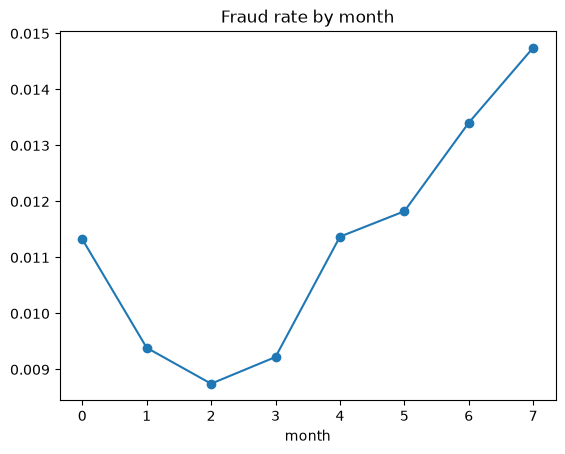

In [7]:
by_month["fraud_rate"].plot(marker="o", title="Fraud rate by month")

In [8]:
num = df.select_dtypes("number").drop(columns=["fraud_bool"])
neg = (num < 0).sum().sort_values(ascending=False)
neg[neg > 0]

intended_balcon_amount          742523
prev_address_months_count       712920
bank_months_count               253635
credit_risk_score                14445
current_address_months_count      4254
session_length_in_minutes         2015
device_distinct_emails_8w          359
velocity_6h                         44
dtype: int64

In [9]:
print(df.isna().sum().sum(), "empty (NaN) cells in total")
df.nunique().sort_values().head(10)

0 empty (NaN) cells in total


device_fraud_count           1
fraud_bool                   2
keep_alive_session           2
foreign_request              2
phone_home_valid             2
has_other_cards              2
email_is_free                2
source                       2
phone_mobile_valid           2
device_distinct_emails_8w    4
dtype: int64

In [10]:
for c in df.select_dtypes(exclude="number").columns:
    print(c, df[c].value_counts().to_dict())

payment_type {'AB': 370554, 'AA': 258249, 'AC': 252071, 'AD': 118837, 'AE': 289}
employment_status {'CA': 730252, 'CB': 138288, 'CF': 44034, 'CC': 37758, 'CD': 26522, 'CE': 22693, 'CG': 453}
housing_status {'BC': 372143, 'BB': 260965, 'BA': 169675, 'BE': 169135, 'BD': 26161, 'BF': 1669, 'BG': 252}
source {'INTERNET': 992952, 'TELEAPP': 7048}
device_os {'other': 342728, 'linux': 332712, 'windows': 263506, 'macintosh': 53826, 'x11': 7228}


## Data Audit: First Findings

- **Dataset:** 1,000,000 rows, 32 columns, and 0 missing values.
- **Fraud rate:** 1.1029% (11,029 fraud cases and 988,971 non-fraud cases).
- **Monthly trend:** Fraud rate increased from 0.87% in month 2 to 1.47% in month 7, despite declining application volume.
- **Negative values:** Several numerical features contain negative values that need investigation before preprocessing.
- **Constant feature:** `device_fraud_count` appears constant and may be removed.
- **Categorical features:** Several columns use anonymised category labels but may still help predict fraud.
- **Modelling plan:** Use a chronological data split, establish a baseline model, and evaluate using precision, recall, F1-score, and PR-AUC because of class imbalance.



In [11]:
cols = ["prev_address_months_count", "current_address_months_count", "bank_months_count",
        "session_length_in_minutes", "device_distinct_emails_8w", "intended_balcon_amount",
        "credit_risk_score", "velocity_6h"]
for c in cols:
    print(c)
    print(df.loc[df[c] < 0, c].value_counts().head(5), "\n")

prev_address_months_count
prev_address_months_count
-1    712920
Name: count, dtype: int64 

current_address_months_count
current_address_months_count
-1    4254
Name: count, dtype: int64 

bank_months_count
bank_months_count
-1    253635
Name: count, dtype: int64 

session_length_in_minutes
session_length_in_minutes
-1.0    2015
Name: count, dtype: int64 

device_distinct_emails_8w
device_distinct_emails_8w
-1    359
Name: count, dtype: int64 

intended_balcon_amount
intended_balcon_amount
-0.882950    3
-1.514280    3
-1.532083    3
-0.554381    3
-1.442709    3
Name: count, dtype: int64 

credit_risk_score
credit_risk_score
-1    488
-2    473
-3    440
-4    421
-5    349
Name: count, dtype: int64 

velocity_6h
velocity_6h
-29.235883     1
-80.690670     1
-130.456928    1
-59.011029     1
-4.387507      1
Name: count, dtype: int64 



In [12]:
for c in ["prev_address_months_count", "bank_months_count", "intended_balcon_amount"]:
    neg = df[c] < 0
    print(c, "| fraud rate if negative:", round(df.loc[neg, "fraud_bool"].mean(), 4),
          "| otherwise:", round(df.loc[~neg, "fraud_bool"].mean(), 4))

prev_address_months_count | fraud rate if negative: 0.0142 | otherwise: 0.0031
bank_months_count | fraud rate if negative: 0.0163 | otherwise: 0.0092
intended_balcon_amount | fraud rate if negative: 0.0131 | otherwise: 0.005


In [13]:
for c in ["intended_balcon_amount", "credit_risk_score", "velocity_6h"]:
    neg = df.loc[df[c] < 0, c]
    print(c, "| negatives:", len(neg), "| distinct negative values:", neg.nunique(),
          "| min:", neg.min(), "| max:", neg.max())
    print(neg.value_counts().head(3).to_dict(), "\n")

intended_balcon_amount | negatives: 742523 | distinct negative values: 737834 | min: -15.530554840076814 | max: -3.987685759376802e-06
{-0.8829498799394292: 3, -1.5142802598222749: 3, -1.5320825951804882: 3} 

credit_risk_score | negatives: 14445 | distinct negative values: 164 | min: -170 | max: -1
{-1: 488, -2: 473, -3: 440} 

velocity_6h | negatives: 44 | distinct negative values: 44 | min: -170.60307235124628 | max: -1.8896144012144305
{-29.235882651923703: 1, -80.69066966650415: 1, -130.45692803910583: 1} 



In [14]:
print(df["customer_age"].value_counts().sort_index())
print()
print(df[["days_since_request", "proposed_credit_limit", "credit_risk_score", "velocity_6h", "velocity_24h", "velocity_4w"]].describe().T[["min", "50%", "max"]])

customer_age
10     20987
20    245855
30    311433
40    238712
50    140353
60     34770
70      6517
80      1297
90        76
Name: count, dtype: int64

                                min          50%           max
days_since_request     4.036860e-09     0.015176     78.456904
proposed_credit_limit  1.900000e+02   200.000000   2100.000000
credit_risk_score     -1.700000e+02   122.000000    389.000000
velocity_6h           -1.706031e+02  5319.769349  16715.565404
velocity_24h           1.300307e+03  4749.921161   9506.896596
velocity_4w            2.825748e+03  4913.436941   6994.764201


In [15]:
print(df.groupby("customer_age")["fraud_bool"].agg(rows="count", fraud_rate="mean"))

                rows  fraud_rate
customer_age                    
10             20987    0.003526
20            245855    0.004901
30            311433    0.008313
40            238712    0.012048
50            140353    0.019985
60             34770    0.033046
70              6517    0.040356
80              1297    0.049345
90                76    0.052632


In [16]:
bins = pd.cut(df["days_since_request"], [-1, 0.01, 0.05, 0.5, 1, 5, 100])
print(df.groupby(bins, observed=True)["fraud_bool"].agg(rows="count", fraud_rate="mean"))

                      rows  fraud_rate
days_since_request                    
(-1.0, 0.01]        342785    0.012889
(0.01, 0.05]        559786    0.009600
(0.05, 0.5]           5942    0.005385
(0.5, 1.0]            9754    0.014456
(1.0, 5.0]           27419    0.021664
(5.0, 100.0]         54314    0.008653


In [17]:
print(df["proposed_credit_limit"].value_counts().sort_index())

proposed_credit_limit
190.0        163
200.0     613854
210.0        607
490.0        870
500.0     135797
510.0       6967
990.0       7580
1000.0     81882
1500.0    145735
1900.0       390
2000.0      6114
2100.0        41
Name: count, dtype: int64
